# Exploratory Data Analysis

This notebook profiles the data sources the ticker-agent pipeline consumes — what each looks like raw, what it becomes after the pipeline's generic transformations, and the targeted tests that fix the pipeline's modeling choices — and closes with the sources that were considered and not used. The conclusions section is the handoff: the pipeline notebook inherits them and imports nothing from here. All sources are documented in [`docs/sources.md`](../docs/sources.md).

## 1. Setup

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
REPO_ROOT = Path.cwd().parent
assert (REPO_ROOT / "pyproject.toml").exists(), "run this notebook from notebooks/"
DATA_PROCESSED = REPO_ROOT / "data" / "processed"

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110


def make_sentiment_pipeline():
    return Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                                  sublinear_tf=True, max_features=10_000)),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced",
                                          random_state=RANDOM_STATE)),
    ])


print("Setup complete.")

C:\Users\18587\Documents\Projects\University of San Diego\AAI-520 Final Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Setup complete.


## 2. Financial PhraseBank — the tone model's training data

The PhraseBank ships four configurations that differ in how many annotators had to agree on the label. The pipeline trains on `sentences_allagree` (unanimous labels); subtracting it from `sentences_50agree` yields the disagreement tail — sentences whose labels annotators disputed and the closest analogue to live headlines.

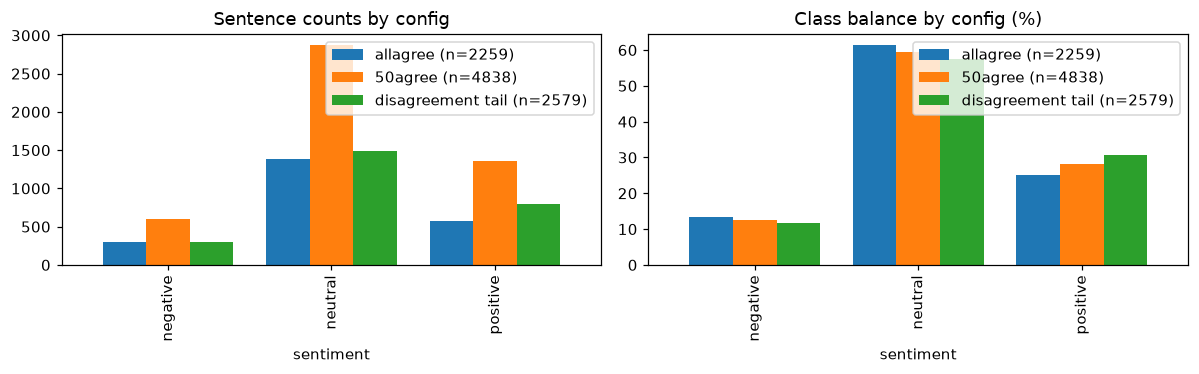

sentiment,negative,neutral,positive
allagree (n=2259),303,1386,570
50agree (n=4838),604,2872,1362
disagreement tail (n=2579),301,1486,792


Sample sentences per class (allagree):
  [negative] Jan. 6 -- Ford is struggling in the face of slowing truck and SUV sales and a surfeit of u
  [negative] Pharmaceuticals group Orion Corp reported a fall in its third-quarter earnings that were h
  [ neutral] According to Gran , the company has no plans to move all production to Russia , although t
  [ neutral] At the request of Finnish media company Alma Media 's newspapers , research manager Jari K
  [positive] For the last quarter of 2010 , Componenta 's net sales doubled to EUR131m from EUR76m for 
  [positive] In the third quarter of 2010 , net sales increased by 5.2 % to EUR 205.5 mn , and operatin


In [2]:
def load_phrasebank(config):
    ds = load_dataset("takala/financial_phrasebank", config, trust_remote_code=True)["train"]
    frame = ds.to_pandas()
    frame["sentiment"] = frame["label"].map(dict(enumerate(ds.features["label"].names)))
    return frame.drop_duplicates(subset="sentence").reset_index(drop=True)


allagree = load_phrasebank("sentences_allagree")
fiftyagree = load_phrasebank("sentences_50agree")
residual = fiftyagree[~fiftyagree["sentence"].isin(set(allagree["sentence"]))].reset_index(drop=True)
order = ["negative", "neutral", "positive"]

balance = pd.DataFrame({f"{name} (n={len(frame)})": frame["sentiment"].value_counts().reindex(order)
                        for name, frame in [("allagree", allagree), ("50agree", fiftyagree), ("disagreement tail", residual)]})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
balance.plot.bar(ax=axes[0], width=0.8, title="Sentence counts by config")
axes[0].set_xlabel("sentiment")
(balance / balance.sum(axis=0) * 100).plot.bar(ax=axes[1], width=0.8, title="Class balance by config (%)")
axes[1].set_xlabel("sentiment")
plt.tight_layout()
plt.show()
display(balance.T)
print("Sample sentences per class (allagree):")
for label in order:
    for sentence in allagree.loc[allagree["sentiment"] == label, "sentence"].head(2):
        print(f"  [{label:>8}] {sentence[:90]}")

## 3. NIFTY — the headline corpus

NIFTY's labels are the S&P 500 ETF's next-day direction (`Rise` / `Fall` / `Neutral` at ±0.5%), not sentence-level sentiment: this is outcome data. The pipeline uses the headline blocks as its 2010–2020 coverage corpus and never uses the labels as sentiment gold.

In [3]:
nifty = load_dataset("raeidsaqur/NIFTY", trust_remote_code=True)
nifty_rows = []
for split in ["train", "valid", "test"]:
    frame = nifty[split].to_pandas()
    frame["split"] = split
    nifty_rows.append(frame)
nifty_all = pd.concat(nifty_rows, ignore_index=True)
nifty_all["n_headlines"] = nifty_all["news"].str.count("\n") + 1

display(pd.DataFrame({"rows": nifty_all.groupby("split").size(),
                      "first date": nifty_all.groupby("split")["date"].min(),
                      "last date": nifty_all.groupby("split")["date"].max()}))
display(nifty_all.groupby("label")["pct_change"].describe().round(4)[["count", "mean", "min", "max"]])
print("Headlines per day:", nifty_all["n_headlines"].describe().round(1).to_dict())
print("One day's headline block (first 5 of", int(nifty_all.iloc[0]["n_headlines"]), "headlines):")
for headline in nifty_all.iloc[0]["news"].split("\n")[:5]:
    print("  •", headline)
print(f"verdict: NIFTY is outcome data — labels are next-day SPY movement, so the pipeline mines coverage and tone from the text and treats direction only as the evaluation target")

,rows,first date,last date
split,,,
test,317,2019-02-13,2020-09-21
train,1477,2010-01-06,2017-06-27
valid,317,2017-06-28,2019-02-12


,count,mean,min,max
label,,,,
Fall,433.0,-0.0134,-0.0957,-0.0050
Neutral,1120.0,0.0003,-0.0050,0.0050
Rise,558.0,0.0117,0.0050,0.0906


Headlines per day: {'count': 2111.0, 'mean': 207.0, 'std': 360.1, 'min': 7.0, '25%': 47.0, '50%': 65.0, '75%': 93.0, 'max': 1627.0}
One day's headline block (first 5 of 18 headlines):
  • China Officials Likely Knew of Bad Milk
  • Sony's CEO on Strategy in 3-D Technology
  • Copper Settles at 16-Month High
  • Gold Ends Near 3-Week High
  • Kraft Gets Antitrust Clearance
verdict: NIFTY is outcome data — labels are next-day SPY movement, so the pipeline mines coverage and tone from the text and treats direction only as the evaluation target


## 4. Market and macro inputs — yfinance prices and FRED DGS10

The pipeline consumes weekly close-to-close bins of AAPL and SPY over the corpus window (2010–2020) and the weekly change of the 10-year Treasury yield. Raw daily rows and their weekly transformation are shown side by side in Section 6.

In [4]:
import yfinance as yf

px = yf.download("AAPL SPY", start="2010-01-01", end="2020-12-31", auto_adjust=True, progress=False)["Close"]
wkpx = px.resample("W-FRI").last()
wkpx.index = wkpx.index.to_period("W-FRI")
wk_ret = wkpx["AAPL"].pct_change().dropna()

stats = pd.Series({
    "AAPL weekly up-rate": f"{(wk_ret > 0).mean():.1%}",
    "annualized volatility": f"{wk_ret.std() * np.sqrt(52):.1%}",
    "skew": round(float(wk_ret.skew()), 2),
    "excess kurtosis": round(float(wk_ret.kurt()), 2),
    "max drawdown": f"{float((wkpx['AAPL'] / wkpx['AAPL'].cummax() - 1).min()):.1%}",
})
fred = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10")
fred_w = pd.Series(pd.to_numeric(fred.iloc[:, 1], errors="coerce").values,
                   index=pd.PeriodIndex(pd.to_datetime(fred.iloc[:, 0]), freq="W-FRI"))
fred_wk = fred_w.groupby(level=0).last()
display(stats.to_frame("value"))
print(f"DGS10: {fred_wk.notna().sum()} weekly levels from {fred_wk.dropna().index.min()} to {fred_wk.dropna().index.max()}, range {fred_wk.min():.2f}–{fred_wk.max():.2f}%")
print("verdict: the weekly up-rate is the always-up structure the pipeline's arms table reports as its floor; the yield series enters only as a market-state column")

,value
AAPL weekly up-rate,58.8%
annualized volatility,28.2%
skew,-0.14
excess kurtosis,1.46
max drawdown,-43.6%


DGS10: 3381 weekly levels from 1961-12-30/1962-01-05 to 2026-10-10/2026-10-16, range 0.55–15.68%
verdict: the weekly up-rate is the always-up structure the pipeline's arms table reports as its floor; the yield series enters only as a market-state column


## 5. SEC EDGAR — filings as earnings-calendar context

The pipeline's earnings desk reads each ticker's submissions history (form and filing date) rendered as recency context. Filings that predate a 2019–2020 session week are historical facts, which makes this input point-in-time for the window.

In [5]:
edgar_cache = DATA_PROCESSED / "edgar_cache" / "AAPL.json"
if edgar_cache.exists():
    edgar = pd.DataFrame(json.loads(edgar_cache.read_text(encoding="utf-8"))["filings"])
else:
    import time
    headers = {"User-Agent": "AAI-520 University Research (psuranthiran@sandiego.edu)", "Accept": "application/json"}
    r = requests.get("https://www.sec.gov/files/company_tickers.json", headers=headers, timeout=30)
    cik = int(next(v["cik_str"] for v in r.json().values() if v["ticker"] == "AAPL"))
    time.sleep(0.4)
    r2 = requests.get(f"https://data.sec.gov/submissions/CIK{cik:010d}.json", headers=headers, timeout=30)
    rec = r2.json()["filings"]["recent"]
    edgar = pd.DataFrame({"form": rec["form"], "date": rec["filingDate"]})
edgar["date"] = pd.to_datetime(edgar["date"])
mat = edgar[edgar["form"].isin(["10-K", "10-Q", "8-K"])].copy()
mat["year"] = mat["date"].dt.year
display(edgar["form"].value_counts().head(8).to_frame("filings"))
display(mat.groupby("year").size().to_frame("material filings (10-K/10-Q/8-K)").tail(6))
probe_date = pd.Timestamp("2019-04-05")
before = mat[mat["date"] <= probe_date].sort_values("date", ascending=False).head(4)
print(f"how the earnings desk sees it at a 2019-04-05 session (4 most recent of 12):")
for _, row in before.iterrows():
    wk = (probe_date - row["date"]).days // 7
    print(f"  {row['form']} ({wk} weeks before now)   [filed {row['date'].date()}]")

,filings
form,
4,1358
8-K,233
10-Q,98
SC 13G/A,60
424B2,58
144,49
PX14A6G,41
3,39


,material filings (10-K/10-Q/8-K)
year,
2021,13
2022,12
2023,10
2024,13
2025,14
2026,9


how the earnings desk sees it at a 2019-04-05 session (4 most recent of 12):
  8-K (4 weeks before now)   [filed 2019-03-04]
  8-K (8 weeks before now)   [filed 2019-02-06]
  10-Q (9 weeks before now)   [filed 2019-01-30]
  8-K (9 weeks before now)   [filed 2019-01-29]


## 6. Generic transformations — the shapes the pipeline consumes

Three previews of raw-becoming-feature: a headline becoming its normalized token set (the unit the corpus funnel, mining, and bins all operate on), daily closes becoming Friday-anchored weekly bins (the label horizon), and the daily yield becoming its weekly change (a market-state column).

In [6]:
import re

TOKEN = re.compile(r"[a-z]{2,}")
print("headline -> tokens (the unit every corpus layer operates on):")
for headline in nifty_all.iloc[0]["news"].split("\n")[:3]:
    toks = TOKEN.findall(headline.lower())
    print(f"  '{headline[:70]}'")
    print(f"    -> {toks[:10]}{' ...' if len(toks) > 10 else ''}")
print("\ndaily close -> weekly bin (Friday-anchored, the label horizon):")
display(px.dropna().head(3))
display(wkpx.dropna().head(3))
print("daily DGS10 -> weekly level and weekly change (a market-state column):")
display(fred_wk.dropna().head(3).to_frame("DGS10 weekly level"))
display(fred_wk.diff().dropna().head(3).to_frame("DGS10 weekly change"))

headline -> tokens (the unit every corpus layer operates on):
  'China Officials Likely Knew of Bad Milk'
    -> ['china', 'officials', 'likely', 'knew', 'of', 'bad', 'milk']
  'Sony's CEO on Strategy in 3-D Technology'
    -> ['sony', 'ceo', 'on', 'strategy', 'in', 'technology']
  'Copper Settles at 16-Month High'
    -> ['copper', 'settles', 'at', 'month', 'high']

daily close -> weekly bin (Friday-anchored, the label horizon):


Ticker,AAPL,SPY
Date,,
2010-01-04,6.400959,84.368996
2010-01-05,6.412027,84.592323
2010-01-06,6.310033,84.651855


Ticker,AAPL,SPY
Date,,
2010-01-02/2010-01-08,6.340243,85.292099
2010-01-09/2010-01-15,6.159289,84.599747
2010-01-16/2010-01-22,5.914628,81.301826


daily DGS10 -> weekly level and weekly change (a market-state column):


,DGS10 weekly level
observation_date,
1961-12-30/1962-01-05,4.02
1962-01-06/1962-01-12,4.08
1962-01-13/1962-01-19,4.11


,DGS10 weekly change
observation_date,
1962-01-06/1962-01-12,0.06
1962-01-13/1962-01-19,0.03
1962-01-20/1962-01-26,0.00


## 7. Targeted tests — the classifier the pipeline trains

The model is fixed (TF-IDF + balanced logistic regression); only the labels change across tests, so the gaps below are label noise, not model capacity. These three numbers are the pipeline's inheritance: the clean-score ceiling, the disagreement-tail operating point, and the weighting choice.

In [7]:
def evaluate_within_config(frame, name):
    x_train, x_test, y_train, y_test = train_test_split(
        frame["sentence"], frame["sentiment"], test_size=0.20,
        stratify=frame["sentiment"], random_state=RANDOM_STATE)
    model = make_sentiment_pipeline().fit(x_train, y_train)
    report = classification_report(y_test, model.predict(x_test), output_dict=True, zero_division=0)
    return {"config": name, "train n": len(x_train), "test n": len(x_test),
            "accuracy": report["accuracy"], "macro-F1": report["macro avg"]["f1-score"],
            **{f"{label} F1": report[label]["f1-score"] for label in order}}


within_config = pd.DataFrame([
    evaluate_within_config(allagree, "allagree (unanimous labels)"),
    evaluate_within_config(fiftyagree, "50agree (majority labels)"),
]).set_index("config")
display(within_config.round(3))

,train n,test n,accuracy,macro-F1,negative F1,neutral F1,positive F1
config,,,,,,,
allagree (unanimous labels),1807,452,0.894,0.862,0.825,0.940,0.821
50agree (majority labels),3870,968,0.749,0.713,0.675,0.809,0.654


In [8]:
allagree_model = make_sentiment_pipeline().fit(allagree["sentence"], allagree["sentiment"])
tail_predictions = allagree_model.predict(residual["sentence"])
tail_report = classification_report(residual["sentiment"], tail_predictions, output_dict=True, zero_division=0)
display(pd.Series({"tail sentences": len(residual), "accuracy": tail_report["accuracy"],
                   "macro-F1": tail_report["macro avg"]["f1-score"],
                   "neutral share of predictions": float(np.mean(tail_predictions == "neutral"))}).round(3))
mismatches = residual.assign(predicted=tail_predictions)
mismatches = mismatches[mismatches["sentiment"] != mismatches["predicted"]]
print(f"example disagreements ({len(mismatches)} of {len(residual)} misclassified):")
for _, row in mismatches.head(3).iterrows():
    print(f"  true [{row['sentiment']:>8}] predicted [{row['predicted']:>8}]  {row['sentence'][:80]}")

tail sentences                  2579.000
accuracy                           0.620
macro-F1                           0.473
neutral share of predictions       0.793
dtype: float64

example disagreements (979 of 2579 misclassified):
  true [negative] predicted [ neutral]  The international electronic industry company Elcoteq has laid off tens of emplo
  true [positive] predicted [ neutral]  With the new production plant the company would increase its capacity to meet th
  true [positive] predicted [ neutral]  FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is aggressively pursuing its growth str


In [9]:
x_train, x_test, y_train, y_test = train_test_split(
    allagree["sentence"], allagree["sentiment"], test_size=0.20,
    stratify=allagree["sentiment"], random_state=RANDOM_STATE)
ablation_rows = []
for weighting in [None, "balanced"]:
    model = Pipeline([("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                                                sublinear_tf=True, max_features=10_000)),
                      ("classifier", LogisticRegression(max_iter=1000, class_weight=weighting,
                                                        random_state=RANDOM_STATE))]).fit(x_train, y_train)
    report = classification_report(y_test, model.predict(x_test), output_dict=True, zero_division=0)
    ablation_rows.append({"class_weight": weighting or "None", "accuracy": report["accuracy"],
                          "macro-F1": report["macro avg"]["f1-score"],
                          **{f"{label} recall": report[label]["recall"] for label in order}})
display(pd.DataFrame(ablation_rows).set_index("class_weight").round(3))

,accuracy,macro-F1,negative recall,neutral recall,positive recall
class_weight,,,,,
None,0.881,0.826,0.656,0.982,0.754
balanced,0.894,0.862,0.852,0.931,0.825


In [10]:
vectorizer = allagree_model.named_steps["tfidf"]
classifier = allagree_model.named_steps["classifier"]
features = np.array(vectorizer.get_feature_names_out())
display(pd.DataFrame({label: features[classifier.coef_[i].argsort()[::-1][:8]]
                      for i, label in enumerate(classifier.classes_)},
                     index=[f"rank {i + 1}" for i in range(8)]))

,negative,neutral,positive
rank 1,down,is,rose
rank 2,decreased,and,increased
rank 3,fell,be,up
rank 4,down from,the,increase
rank 5,decreased to,will,grew
rank 6,dropped,will be,up from
rank 7,lower,approximately,rose to
rank 8,decreased by,not,to


## 8. Zero-shot LLM versus the classifier

One batched Gemini call (temperature 0) classifies a sample of the disagreement tail zero-shot, beside the trained classifier on the same sentences. The comparison frames the division of labor the pipeline adopts: the cheap statistical model owns tone, and the LLM is spent only where judgment is required.

In [11]:
import os
from dotenv import load_dotenv

load_dotenv(REPO_ROOT / ".env")
gemini_api_key = os.environ.get("GEMINI_API_KEY")
zs_sample = residual.sample(40, random_state=RANDOM_STATE)
zs_true = zs_sample["sentiment"].to_numpy()
zs_clf = allagree_model.predict(zs_sample["sentence"])

if not gemini_api_key:
    print("GEMINI_API_KEY not set — comparison skipped; the classical numbers stand alone")
else:
    from google import genai
    from google.genai import types

    client = genai.Client(api_key=gemini_api_key)
    numbered = "\n".join(f"{i + 1}. {s}" for i, s in enumerate(zs_sample["sentence"]))
    prompt = ("Classify the sentiment of each numbered financial news sentence as positive, neutral, or negative.\n"
              'Respond with JSON only, no prose: {"labels": ["positive", ...]} with exactly one label per sentence, in order.\n\n'
              + numbered)
    reply = client.models.generate_content(model="gemini-3.5-flash-lite", contents=prompt,
                                           config=types.GenerateContentConfig(temperature=0.0)).text
    try:
        payload = json.loads(reply[reply.find("{"):reply.rfind("}") + 1])
        zs_llm = [str(x).lower() for x in payload["labels"]][:len(zs_sample)]
        while len(zs_llm) < len(zs_sample):
            zs_llm.append("neutral")
        display(pd.Series({
            "classifier accuracy": float(np.mean(np.asarray(zs_clf) == zs_true)),
            "zero-shot LLM accuracy": float(np.mean(np.asarray(zs_llm) == zs_true)),
            "agreement rate": float(np.mean(np.asarray(zs_llm) == np.asarray(zs_clf))),
            "LLM neutral share": float(np.mean(np.asarray(zs_llm) == "neutral")),
        }).round(3))
        print("verdict: measured and reported as found — the comparison sizes the gap between the trained classifier and a raw LLM on disputed-label text, and either way the pipeline keeps tone in the cheap model")
    except (json.JSONDecodeError, KeyError):
        print("LLM reply could not be parsed — comparison skipped; reply verbatim:")
        print(reply[:400])

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


classifier accuracy       0.50
zero-shot LLM accuracy    0.75
agreement rate            0.55
LLM neutral share         0.55
dtype: float64

verdict: measured and reported as found — the comparison sizes the gap between the trained classifier and a raw LLM on disputed-label text, and either way the pipeline keeps tone in the cheap model


## 9. Sources considered and not used

Three sources were probed and set aside, each with the measured reason: Yahoo Finance's news search (title-only, drifting), Alpha Vantage (duplicates the yfinance feed behind a key), and NewsAPI.org (no archival window).

In [12]:
import yfinance as yf

search = yf.Search("AAPL", news_count=15)
news = pd.DataFrame([{"title": item.get("title") or "", "publisher": item.get("publisher") or "",
                      "summary_empty": not (item.get("summary") or item.get("description") or "").strip()}
                     for item in (search.news or [])])
print(f"yf.Search: {len(news)} articles | empty-summary rate {news['summary_empty'].mean():.0%} | distinct publishers {news['publisher'].nunique()}")
display(news[["title", "publisher"]].head(5))
print("verdict: classification would be title-only on drifting search results — the archival NIFTY corpus won")

yf.Search: 15 articles | empty-summary rate 100% | distinct publishers 7


,title,publisher
0,AAPL Stock Adds 1% As It Prepares To Tackle UK Regulators Over Apple Pay Dominance,Stocktwits
1,AAPL Stock Gains As Strong Demand Reportedly Pushes iPhone Duo Delivery To December,Stocktwits
2,Apple (AAPL) Sees $365.1 Million in Net ETF Buying on Oct. 14,GuruFocus.com
3,Apple (AAPL) Gets Court Order For AI Hiring Records In Trade Secrets Fight,Simply Wall St.
4,Apple (AAPL): Can Longer iPhone Ownership Still Produce More Profit per Customer?,Insider Monkey


verdict: classification would be title-only on drifting search results — the archival NIFTY corpus won


In [13]:
r = requests.get("https://www.alphavantage.co/query",
                 params={"function": "TIME_SERIES_DAILY", "symbol": "IBM", "apikey": "demo"}, timeout=30)
payload = r.json()
if "Time Series (Daily)" in payload:
    latest_date, latest_row = next(iter(payload["Time Series (Daily)"].items()))
    print(f"Alpha Vantage (demo key): daily series works — IBM {latest_date} close ${float(latest_row['4. close']):.2f}, {len(payload['Time Series (Daily)']):,} rows returned")
else:
    print("Alpha Vantage (demo key):", str(payload)[:200])
print("verdict: a free key serves the same daily OHLCV yfinance already provides, and its sentiment feeds are live-window only — not used for the 2010–2020 window")

Alpha Vantage (demo key): daily series works — IBM 2026-10-16 close $232.08, 100 rows returned
verdict: a free key serves the same daily OHLCV yfinance already provides, and its sentiment feeds are live-window only — not used for the 2010–2020 window


In [14]:
r = requests.get("https://newsapi.org/v2/everything", params={"q": "apple", "apiKey": "missing"}, timeout=30)
try:
    body = r.json()
    print(f"NewsAPI.org without a key: HTTP {r.status_code} — {body.get('code')}: {body.get('message')}")
except ValueError:
    print(f"NewsAPI.org without a key: HTTP {r.status_code}")
print("verdict: free tier requires a key and serves a rolling ~30-day window — cannot backfill 2010–2020; recorded as a live-only extension")

NewsAPI.org without a key: HTTP 401 — apiKeyInvalid: Your API key is invalid or incorrect. Check your key, or go to https://newsapi.org to create a free API key.


verdict: free tier requires a key and serves a rolling ~30-day window — cannot backfill 2010–2020; recorded as a live-only extension


## 10. Conclusions for the pipeline

The corpus and market inputs carry real, learnable structure the pipeline references — tone the classifier can read, coverage that bursts, an always-up market regime — while no single source carries next-week direction; that measured absence is the pipeline's floor, not a gap in this analysis.

In [15]:
summary = pd.DataFrame({
    "PhraseBank allagree / 50agree / tail": [f"{len(allagree)} / {len(fiftyagree)} / {len(residual)}"],
    "within-config accuracy (allagree / 50agree)": [" / ".join(f"{v:.3f}" for v in within_config["accuracy"])],
    "disagreement-tail transfer accuracy": [f"{float(np.mean(tail_predictions == residual['sentiment'].to_numpy())):.3f}"],
    "NIFTY rows (train/valid/test)": ["/".join(str(int((nifty_all['split'] == s).sum())) for s in ["train", "valid", "test"])],
    "AAPL weekly up-rate 2010–2020": [f"{(wk_ret > 0).mean():.1%}"],
    "AAPL annualized weekly volatility": [f"{wk_ret.std() * np.sqrt(52):.1%}"],
    "EDGAR filings cached for AAPL": [f"{len(edgar):,} ({edgar['date'].min().date()} to {edgar['date'].max().date()})"],
}, index=["value"]).T
summary.index.name = "quantity"
display(summary)
print("1. Train the tone model on allagree with balanced weights; report macro-F1 within config.")
print("2. The disagreement-tail transfer is the operating point on real headlines; the pipeline states it wherever tone is interpreted.")
print("3. NIFTY is outcome data: coverage and tone come from the text, direction only from realized returns.")
print("4. The weekly up-rate defines the always-up floor the pipeline's arms table must beat and does not.")
print("5. EDGAR filings predate the sessions, so the earnings desk's recency context is point-in-time.")
print("6. yf.Search, Alpha Vantage, and NewsAPI were probed and set aside for the measured reasons above.")
print("7. PhraseBank and NIFTY load from their Hugging Face canonical copies; the Financial PhraseBank is also distributed on Kaggle (ankurzing/sentiment-analysis-for-financial-news), and every source used here is cited in docs/sources.md.")

,value
quantity,
PhraseBank allagree / 50agree / tail,2259 / 4838 / 2579
within-config accuracy (allagree / 50agree),0.894 / 0.749
disagreement-tail transfer accuracy,0.620
NIFTY rows (train/valid/test),1477/317/317
AAPL weekly up-rate 2010–2020,58.8%
AAPL annualized weekly volatility,28.2%
EDGAR filings cached for AAPL,"2,266 (1994-01-26 to 2026-10-15)"


1. Train the tone model on allagree with balanced weights; report macro-F1 within config.
2. The disagreement-tail transfer is the operating point on real headlines; the pipeline states it wherever tone is interpreted.
3. NIFTY is outcome data: coverage and tone come from the text, direction only from realized returns.
4. The weekly up-rate defines the always-up floor the pipeline's arms table must beat and does not.
5. EDGAR filings predate the sessions, so the earnings desk's recency context is point-in-time.
6. yf.Search, Alpha Vantage, and NewsAPI were probed and set aside for the measured reasons above.
7. PhraseBank and NIFTY load from their Hugging Face canonical copies; the Financial PhraseBank is also distributed on Kaggle (ankurzing/sentiment-analysis-for-financial-news), and every source used here is cited in docs/sources.md.
